In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    RocCurveDisplay
)

In [3]:
df = pd.read_csv("Anime.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nFirst Five Anime:")
print(df[[
    "Name", "Type", "Episodes", "Release_season", "Release_year", "Rating"
]].head().to_string(index=False))

Dataset Shape: (18495, 17)

Columns: ['Rank', 'Name', 'Japanese_name', 'Type', 'Episodes', 'Studio', 'Release_season', 'Tags', 'Rating', 'Release_year', 'End_year', 'Description', 'Content_Warning', 'Related_Mange', 'Related_anime', 'Voice_actors', 'staff']

First Five Anime:
                                                       Name  Type  Episodes Release_season  Release_year  Rating
Demon Slayer: Kimetsu no Yaiba - Entertainment District Arc TV          NaN          Fall         2021.0    4.60
                             Fruits Basket the Final Season TV         13.0         Spring        2021.0    4.60
                                            Mo Dao Zu Shi 3 Web        12.0            NaN        2021.0    4.58
                           Fullmetal Alchemist: Brotherhood TV         64.0         Spring        2009.0    4.58
                        Attack on Titan 3rd Season: Part II TV         10.0         Spring        2019.0    4.57


In [4]:
# Keep anime with a known rating
df = df.dropna(subset=["Rating"]).copy()

# Strip spaces from values such as "TV   " and "Fall "
for column in ["Type", "Release_season"]:
    df[column] = df[column].fillna("Unknown").str.strip()

df["Tags"] = df["Tags"].fillna("")

# 1 = rating >= 4.0, 0 = rating < 4.0
rating_cutoff = 4.0
df["Highly_Rated"] = (df["Rating"] >= rating_cutoff).astype(int)

class_names = ["Below 4.0", "4.0 or Above"]

print("Anime with Ratings:", len(df))
print("\nRating Class Counts:")
print(
    df["Highly_Rated"].value_counts().sort_index()
    .rename(index=dict(enumerate(class_names)))
)

Anime with Ratings: 15364

Rating Class Counts:
Highly_Rated
Below 4.0       14464
4.0 or Above      900
Name: count, dtype: int64


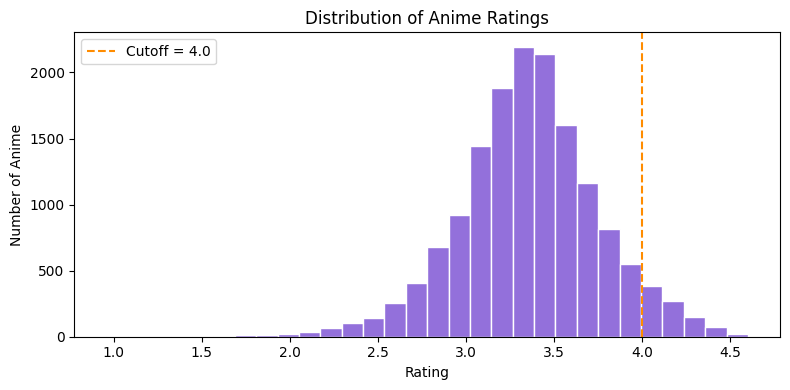

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(df["Rating"], bins=30, color="mediumpurple", edgecolor="white")
ax.axvline(
    rating_cutoff, color="darkorange", linestyle="--", label="Cutoff = 4.0"
)

ax.set_title("Distribution of Anime Ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Anime")
ax.legend()

plt.tight_layout()
plt.show()

In [6]:
numeric_columns = ["Episodes", "Release_year"]
category_columns = ["Type", "Release_season"]
feature_columns = numeric_columns + category_columns + ["Tags"]

X = df[feature_columns]
y = df["Highly_Rated"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("\nTest Class Counts:")
print(y_test.value_counts().sort_index())

Training Data: (12291, 5)
Testing Data: (3073, 5)

Test Class Counts:
Highly_Rated
0    2893
1     180
Name: count, dtype: int64


In [7]:
def split_tags(text):
    return [tag.strip() for tag in text.split(",") if tag.strip()]

numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

tag_encoder = CountVectorizer(
    tokenizer=split_tags,
    token_pattern=None,
    binary=True,
    max_features=40
)

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_columns),
    ("tags", tag_encoder, "Tags")
])

In [8]:
model = make_pipeline(
    preprocessor,
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        cache_size=512
    )
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
decision_scores = model.decision_function(X_test)

print("SVM Training Completed!")
print("First 10 Predictions:", y_pred[:10])

SVM Training Completed!
First 10 Predictions: [1 0 0 0 0 0 0 0 1 0]


In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0)
}

print("\nEvaluation Metrics:")
for name, score in metrics.items():
    print(f"{name}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

Confusion Matrix:
[[2526  367]
 [  45  135]]

True Negatives: 2526
False Positives: 367
False Negatives: 45
True Positives: 135

Evaluation Metrics:
Accuracy: 0.8659
Balanced Accuracy: 0.8116
Precision: 0.2689
Recall: 0.7500
F1-Score: 0.3959

Classification Report:
              precision    recall  f1-score   support

   Below 4.0       0.98      0.87      0.92      2893
4.0 or Above       0.27      0.75      0.40       180

    accuracy                           0.87      3073
   macro avg       0.63      0.81      0.66      3073
weighted avg       0.94      0.87      0.89      3073



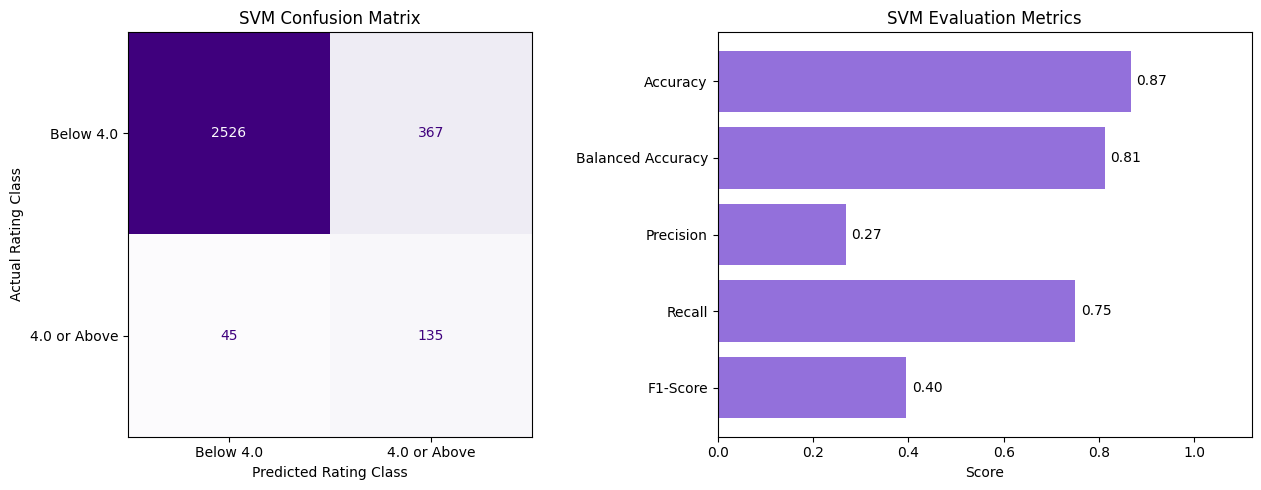

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=axes[0], cmap="Purples", values_format="d", colorbar=False)

axes[0].set_title("SVM Confusion Matrix")
axes[0].set_xlabel("Predicted Rating Class")
axes[0].set_ylabel("Actual Rating Class")

bars = axes[1].barh(list(metrics.keys()), list(metrics.values()), color="mediumpurple")
axes[1].bar_label(bars, fmt="%.2f", padding=4)
axes[1].set_xlim(0, 1.12)
axes[1].invert_yaxis()
axes[1].set_title("SVM Evaluation Metrics")
axes[1].set_xlabel("Score")

plt.tight_layout()
plt.show()

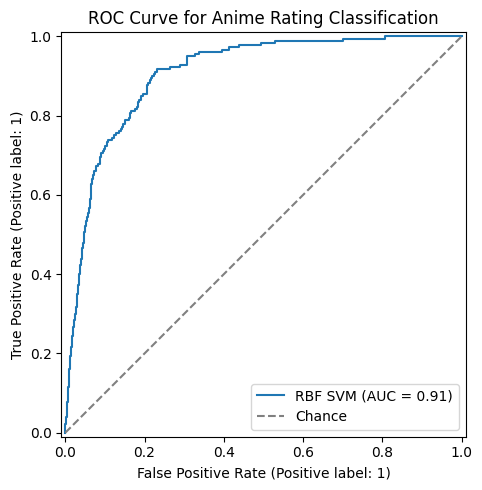

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    decision_scores,
    name="RBF SVM",
    ax=ax
)

ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set_title("ROC Curve for Anime Rating Classification")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

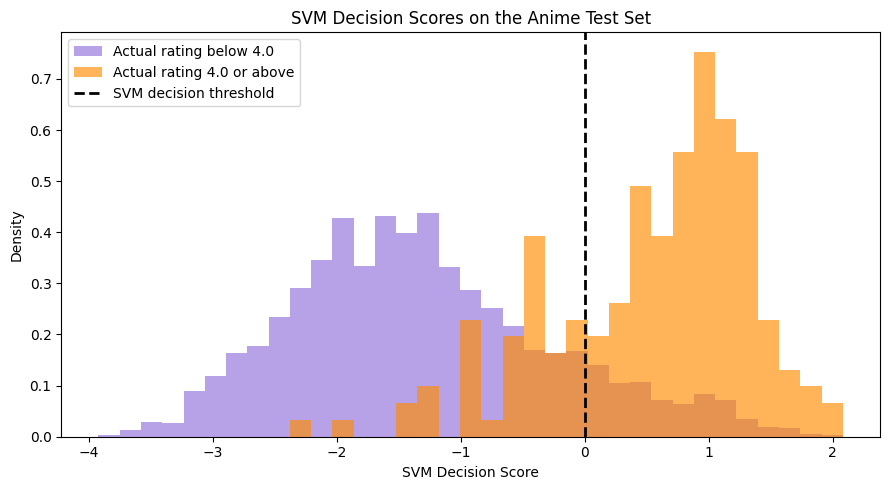

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    decision_scores[y_test.to_numpy() == 0],
    bins=35,
    density=True,
    alpha=0.65,
    color="mediumpurple",
    label="Actual rating below 4.0"
)

ax.hist(
    decision_scores[y_test.to_numpy() == 1],
    bins=np.histogram_bin_edges(decision_scores[y_test.to_numpy() == 0], bins=35),
    density=True,
    alpha=0.65,
    color="darkorange",
    label="Actual rating 4.0 or above"
)

ax.axvline(0, color="black", linestyle="--", linewidth=2,
           label="SVM decision threshold")

ax.set_title("SVM Decision Scores on the Anime Test Set")
ax.set_xlabel("SVM Decision Score")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()